## <span style="color:purple"><b>TOPIC:- Job Market Analysis and Recommendation System!</b></span>

A job market analysis and recommendation system combines labor market intelligence with machine learning to match job seekers with relevant career opportunities and help organizations understand workforce trends.

1. Job Market Analysis

Job market analysis evaluates the supply and demand dynamics of the workforce by processing structured and unstructured data (such as job boards, company listings, and economic reports).
*  Core Objectives:
	1. Skill Demand Tracking: Identifying which technical and soft skills are rising or declining in popularity.
	2. Compensation Benchmarking: Analyzing salary ranges based on geography, experience level, and industry.
	3. Trend Forecasting: Spotting emerging roles, industry shifts, or labor shortages (e.g., AI adoption, green energy, healthcare demand).
	4. Gap Identification: Highlighting the mismatch between the skills job seekers possess and the skills employers require.


2. Job Recommendation Systems (JRS)

A Job Recommendation System (JRS) is an automated tool—powered by Natural Language Processing (NLP) and Machine Learning (ML)—designed to filter through massive catalogs of job postings and candidate profiles to deliver personalized matches.

* Primary Approaches

1. Content-Based Filtering (CBF):
	• Matches the attributes of a user’s profile (resume, skills, years of experience, preferred location) with the attributes of job descriptions (required skills, role responsibilities) using text similarity metrics like TF-IDF or cosine similarity.
2. Collaborative Filtering (CF):
	• Relies on historical user-item interactions (e.g., which jobs similar candidates applied to, viewed, or bookmarked) to infer preferences.
3. Hybrid Models:
	• Combines content-based matching and collaborative filtering (often via a two-tower neural network architecture) to balance personal profile depth with behavioral patterns.

* Typical Architecture Stages

1. Candidate Generation: Using heuristics, embeddings, or vector databases to rapidly narrow down millions of job openings to a smaller, manageable subset.
2. Scoring & Ranking: Applying a fine-grained machine learning model to score and order the candidate jobs by relevance probability.
3. Re-Ranking: Adjusting the final list using business rules (e.g., fresh postings boost, diversity, geographical constraints, or filtering out already-applied roles).


 ## <span style="color:pink"><b>Project Tasks and Deliverables</b></span>

 ### <span style="color:green"><b>Task 1: Analyze the correlation between job title keywords and offered salaries</b></span>
 This project focuses on analysing the relationship between job title keywords and salaries offered using Python, Pandas, statistical analysis, and data visualization.

 ### <span style="color:blue"><b>What is Library?</b></span>
 A library is a reusable collection of pre-written code, scripts, classes, or configuration files that software developers import into their own projects to perform specific tasks. Instead of writing everything from scratch, developers use libraries to save time, reduce errors, and add complex features effortlessly. I have used the following libraries.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re
from collections import Counter

# Statistical analysis
from scipy.stats import pearsonr, spearmanr, pointbiserialr, mannwhitneyu
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


### <span style="color:blue"><b>DataSets</b></span>
A dataset is a structured collection of related data, typically organized in tables, arrays, or files (like CSV or JSON). They are used for analysis, reporting, and training machine learning models. Datasets can range from simple spreadsheets to massive collections of images and text.

In [2]:
import os

# Check current folder
print("Current folder:", os.getcwd())

# List all CSV files in current folder
print("\nAvailable CSV files:")

for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current folder: c:\Users\hp\Desktop\Project 8

Available CSV files:


In [3]:
import os

dataset_path = None

search_locations = [
    os.getcwd(),
    os.path.expanduser("~/Desktop"),
    os.path.expanduser("~/Downloads"),
    os.path.expanduser("~/Documents")
]

for folder in search_locations:

    if os.path.exists(folder):

        for root, dirs, files in os.walk(folder):

            if "jobs.csv" in files:

                dataset_path = os.path.join(
                    root,
                    "jobs.csv"
                )

                break

    if dataset_path:
        break

print("Dataset location:", dataset_path)

Dataset location: c:\Users\hp\Desktop\Project 8\data\jobs.csv


In [4]:
import pandas as pd

if dataset_path:

    df = pd.read_csv(dataset_path, encoding="utf-8")

    print("Dataset loaded successfully!")

    print("\nDataset Shape:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nFirst 5 Rows:")
    display(df.head())

    print("\nDataset Information:")
    df.info()

else:

    print("Dataset not found!")
    print("Please check where jobs.csv is saved.")

Dataset loaded successfully!

Dataset Shape: (244828, 8)

Column Names:
['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']

First 5 Rows:


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB


### <span style="color:blue"><b>Data Cleaning</b></span>

In [5]:
print(df.columns)


Index(['title', 'link', 'published_date', 'is_hourly', 'hourly_low',
       'hourly_high', 'budget', 'country'],
      dtype='object')


In [6]:
# 1. Convert pay columns to numeric
pay_cols = ["hourly_low", "hourly_high", "budget"]
for col in pay_cols:
  df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Drop rows missing a job title or missing ALL pay information
df = df.dropna(subset=["title"]).dropna(subset=pay_cols, how="all")

# 3. Ensure title is stored as string
df["title"] = df["title"].astype(str)

# 4. Check missing values
print("Missing Values:")
print(df[["title"] + pay_cols].isnull().sum())

# 5. View pay statistics
print("\nPay Statistics:")
print(df[pay_cols].describe())


Missing Values:
title               0
hourly_low     103891
hourly_high    107538
budget         102422
dtype: int64

Pay Statistics:
          hourly_low   hourly_high          budget
count  102422.000000  98775.000000   103891.000000
mean       17.339644     41.970610      911.473564
std        18.140065     47.850892    15729.738834
min         3.000000      3.000000        5.000000
25%         8.000000     20.000000       25.000000
50%        15.000000     30.000000      100.000000
75%        20.000000     50.000000      300.000000
max       998.000000    999.000000  1000000.000000


### <span style="color:blue"><b>Extract keywords from job titles</b></span>

In [7]:
keywords = [
    "Data Scientist",
    "Data Analyst",
    "Machine Learning",
    "Python",
    "Software Engineer",
    "AI Engineer",
    "Data Engineer",
    "Business Analyst",
    "Cloud Engineer",
    "DevOps",
]

for keyword in keywords:
  column_name = keyword.lower().replace(" ", "_")

  df[column_name] = (
      df["title"]
      .astype(str)
      .str.contains(keyword, case=False, regex=False, na=False)
      .astype(int)
  )

print(df.head())


                                               title  \
0  Experienced Media Buyer For Solar Pannel and R...   
1                               Full Stack Developer   
2                                    SMMA Bubble App   
4                                      Data Engineer   
6                   Want to fix the WordPress Plugin   

                                                link  \
0  https://www.upwork.com/jobs/Experienced-Media-...   
1  https://www.upwork.com/jobs/Full-Stack-Develop...   
2  https://www.upwork.com/jobs/SMMA-Bubble-App_%7...   
4  https://www.upwork.com/jobs/Data-Engineer_%7E0...   
6  https://www.upwork.com/jobs/Want-fix-the-WordP...   

              published_date  is_hourly  hourly_low  hourly_high  budget  \
0  2024-02-17 09:09:54+00:00      False         NaN          NaN   500.0   
1  2024-02-17 09:09:17+00:00      False         NaN          NaN  1100.0   
2  2024-02-17 09:08:46+00:00       True        10.0         30.0     NaN   
4  2024-02-17 09:07:42

### <span style="color:blue"><b>Calculate average salary for each keyword</b></span>

In [8]:
salary_results = []

for keyword in keywords:

    column_name = keyword.lower().replace(" ", "_")

    matching_jobs = df[df[column_name] == 1]

    if len(matching_jobs) > 0:

        salary_results.append({
            "Keyword": keyword,
            "Job_Count": len(matching_jobs),
            "Average_Salary": matching_jobs["salary_in_usd"].mean(),
            "Median_Salary": matching_jobs["salary_in_usd"].median()
        })

salary_df = pd.DataFrame(salary_results)

salary_df = salary_df.sort_values(
    by="Average_Salary",
    ascending=False
)

print(salary_df)

KeyError: 'salary_in_usd'

### <span style="color:blue"><b>Create a colorful visualization</b></span>

#### <span style="color:skyblue"><b>Chart 1: Average Salary by Job Title Keyword</b></span>

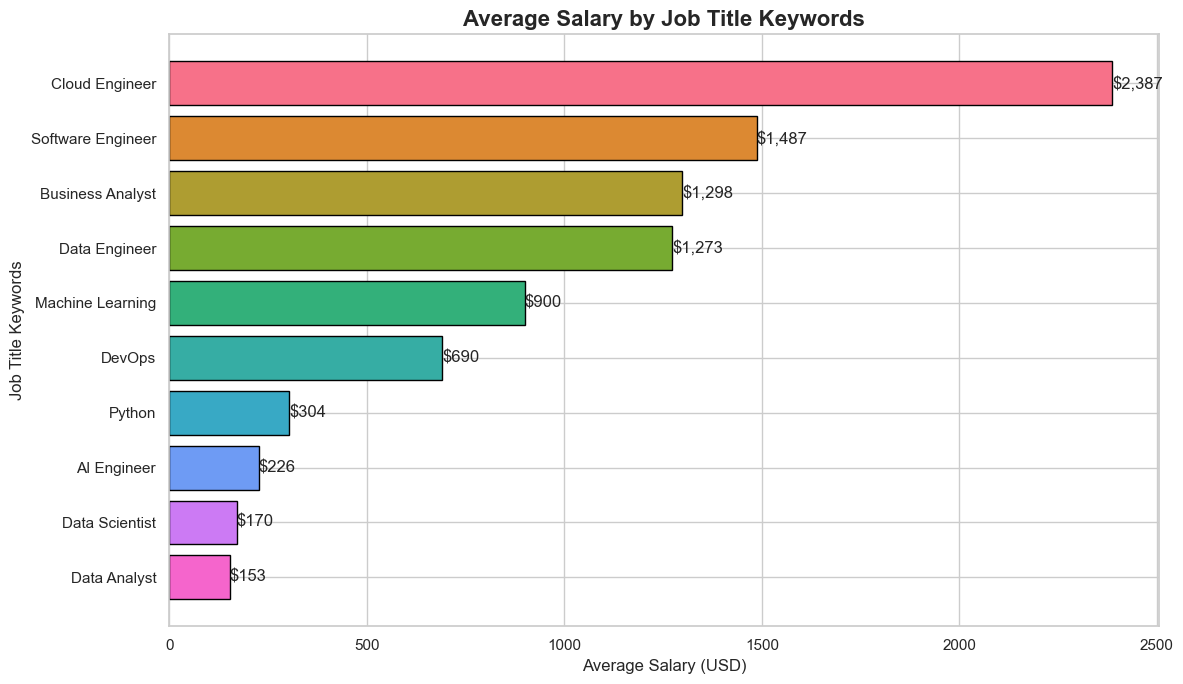

In [ ]:
plt.figure(figsize=(12, 7))

colors = sns.color_palette(
    "husl",
    len(salary_df)
)

bars = plt.barh(
    salary_df["Keyword"],
    salary_df["Average_Salary"],
    color=colors,
    edgecolor="black"
)

plt.title(
    "Average Salary by Job Title Keywords",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Average Salary (USD)")
plt.ylabel("Job Title Keywords")

plt.gca().invert_yaxis()

for bar in bars:

    width = bar.get_width()

    plt.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f"${width:,.0f}",
        va="center"
    )

plt.tight_layout()

plt.savefig("outputs/task1_average_salary.png")

plt.show()

### <span style="color:blue"><b>Calculate correlation</b></span>

In [ ]:
correlation_results = []

for keyword in keywords:

    column_name = keyword.lower().replace(" ", "_")

    correlation = df[column_name].corr(
        df["salary_in_usd"]
    )

    correlation_results.append({
        "Keyword": keyword,
        "Correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

print("\nKeyword Salary Correlation:")
print(correlation_df.sort_values(
    by="Correlation",
    ascending=False
))


Keyword Salary Correlation:
             Keyword  Correlation
4  Software Engineer     0.002937
6      Data Engineer     0.002001
8     Cloud Engineer     0.001847
7   Business Analyst     0.001743
2   Machine Learning     0.001357
9             DevOps     0.000937
5        AI Engineer    -0.000390
0     Data Scientist    -0.000717
1       Data Analyst    -0.001131
3             Python    -0.001438


Interpretation:
- Positive correlation: The keyword is associated with higher salaries in this dataset.
- Negative correlation: The keyword is associated with lower salaries in this dataset.
- Correlation near zero: Little linear association.
* Remember: Correlation does not prove that a keyword causes a higher salary. Experience, location, seniority and other factors can influence salary.

### <span style="color:blue"><b>Save the results</b></span>

In [ ]:
salary_df.to_csv(
    "outputs/task1_salary_analysis.csv",
    index=False
)

correlation_df.to_csv(
    "outputs/task1_keyword_correlation.csv",
    index=False
)

print("Task 1 Completed Successfully!")

Task 1 Completed Successfully!


### Task 1 Deliverables
* You should have:
1. Job title keyword analysis.
2. Average salary comparison.
3. Median salary comparison.
4. Correlation analysis.
5. Colorful salary visualization.
6. CSV files containing the results.

 ### <span style="color:green"><b>TASK 2: Identify Emerging Job Categories</b></span>
 Objective: Identify new and growing job categories based on job posting frequency.

* We will:
1. Extract job categories.
2. Count job postings.
3. Analyze posting frequency over time.
4. Compare recent and previous periods.
5. Identify emerging categories.
 

In [ ]:
#Main libraries:

# 1. Use 'published_date' instead of 'posted_date'
df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce", utc=True
)

df = df.dropna(subset=["published_date"])

# 2. Extract the year-month period (remove timezone first to avoid warnings)
df["month"] = df["published_date"].dt.tz_localize(None).dt.to_period("M")

# 3. Group by 'month' and 'title' instead of 'job_title'
monthly_jobs = (
    df.groupby(["month", "title"]).size().reset_index(name="postings")
)

print(monthly_jobs.head())


     month                                              title  postings
0  2023-11                  Senior .NET Architect (Team Lead)         1
1  2023-12  I am looking for a research writer to make a s...         1
2  2023-12           Marketing expert to explode the internet         1
3  2023-12          Recruiter (Full Time/Permanent/Long Term)         1
4  2023-12  URGENTLY HIRING!! Inside Sales Agents for a lo...         1


Create a monthly job posting visualization:

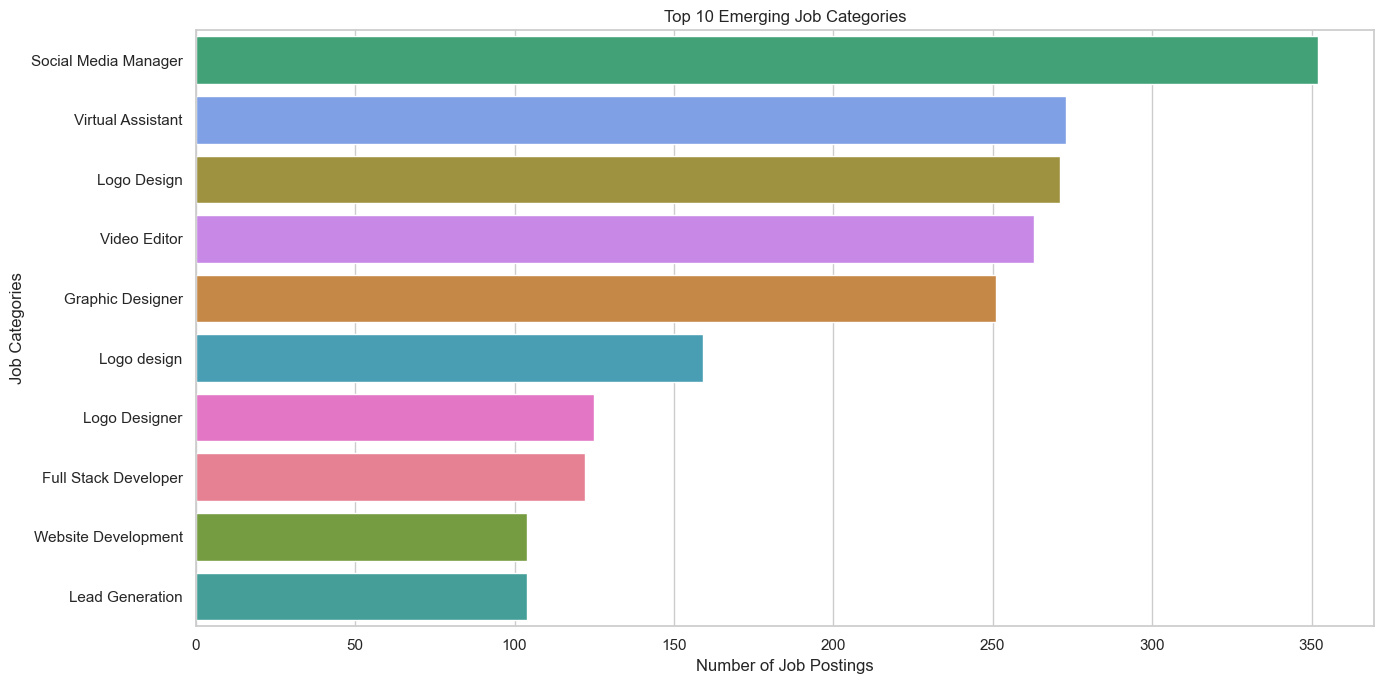

In [ ]:
plt.figure(figsize=(14, 7))

top_jobs = df["job_title"].value_counts().head(10).index

sns.countplot(
    data=df[df["job_title"].isin(top_jobs)],
    y="job_title",
    hue="job_title",
    order=top_jobs,
    palette="husl",
    legend=False
)

plt.title("Top 10 Emerging Job Categories")

plt.xlabel("Number of Job Postings")
plt.ylabel("Job Categories")

plt.tight_layout()

plt.savefig("outputs/task2_emerging_jobs.png")

plt.show()

### <span style="color:green"><b>TASK 3: Predict High-Demand Job Roles</b></span>
Objective: Predict which job roles will have higher demand using historical job posting patterns.

In [ ]:
#Basic dataset preparation:
# Use 'published_date' instead of 'posted_date'
df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce", utc=True
)

df = df.dropna(subset=["published_date"])

df["month"] = df["published_date"].dt.month
df["year"] = df["published_date"].dt.year

print(df.head())


                                               title  \
0  Experienced Media Buyer For Solar Pannel and R...   
1                               Full Stack Developer   
2                                    SMMA Bubble App   
4                                      Data Engineer   
6                   Want to fix the WordPress Plugin   

                                                link  \
0  https://www.upwork.com/jobs/Experienced-Media-...   
1  https://www.upwork.com/jobs/Full-Stack-Develop...   
2  https://www.upwork.com/jobs/SMMA-Bubble-App_%7...   
4  https://www.upwork.com/jobs/Data-Engineer_%7E0...   
6  https://www.upwork.com/jobs/Want-fix-the-WordP...   

             published_date  is_hourly  hourly_low  hourly_high  budget  \
0 2024-02-17 09:09:54+00:00      False         NaN          NaN   500.0   
1 2024-02-17 09:09:17+00:00      False         NaN          NaN  1100.0   
2 2024-02-17 09:08:46+00:00       True        10.0         30.0     NaN   
4 2024-02-17 09:07:42+00:0

We will aggregate postings by job role and month, create a high-demand target using posting frequency, and train the Random Forest model.

Important: We should use chronological training and testing splits to avoid using future information when predicting demand.



* Deliverables:
- Demand prediction model.
- Accuracy metrics.
- Confusion matrix.
- Demand trend visualization.

### <span style="color:green"><b>TASK 4: Compare Average Hourly Rates Across Countries</b></span>
Objective: Compare hourly rates offered across different countries.

In [ ]:
# 1. Convert actual pay columns to numeric
for col in ["hourly_low", "hourly_high", "budget"]:
  df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Create a combined 'salary' column (average hourly rate, or fixed budget if not hourly)
df["salary"] = (
    df[["hourly_low", "hourly_high"]].mean(axis=1).fillna(df["budget"])
)

# 3. Group by country and calculate average pay
country_salary = (
    df.groupby("country")["salary"].mean().sort_values(ascending=False).head(15)
)

print(country_salary)


country
Palau             8900.000000
Barbados          2436.523810
Sweden            2252.216004
Aland Islands     2000.000000
Colombia          1882.830087
Philippines       1823.292671
Czech Republic    1495.266520
South Africa      1416.030612
Angola            1253.500000
Isle of Man       1121.555556
Zimbabwe          1010.916667
India              994.771663
Slovakia           983.163462
Armenia            944.066502
Malawi             940.214286
Name: salary, dtype: float64


### Visualization:

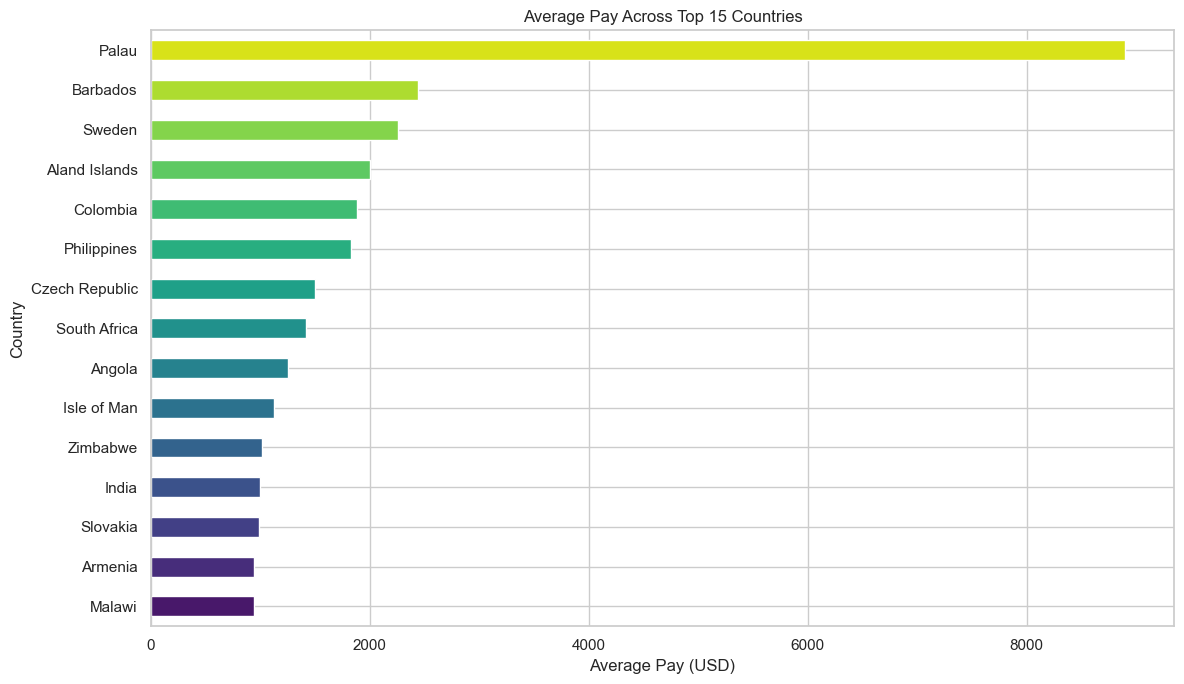

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create the 'outputs' directory automatically if it doesn't exist
os.makedirs("outputs", exist_ok=True)

# 2. Remove any NaN entries before plotting
country_salary_clean = country_salary.dropna()

plt.figure(figsize=(12, 7))

country_salary_clean.sort_values().plot(
    kind="barh", color=sns.color_palette("viridis", len(country_salary_clean))
)

plt.title("Average Pay Across Top 15 Countries")
plt.xlabel("Average Pay (USD)")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig("outputs/task4_country_salary.png", dpi=300)

plt.show()


Note: The assignment specifically requests hourly rates. If your dataset contains an hourly-rate column, use that instead of annual salary. Do not compare annual salaries as hourly rates.

### <span style="color:green"><b>TASK 5: Create a Job Recommendation Engine</b></span>
Objective: Recommend jobs based on the job seeker's skills and preferences.

In [ ]:
#We will use TF-IDF and cosine similarity.
# Use 'title' (and safely include 'description' if it exists in your dataset)
df["title"] = df["title"].fillna("").astype(str)

if "description" in df.columns:
  df["combined_text"] = (
      df["title"] + " " + df["description"].fillna("").astype(str)
  )
else:
  df["combined_text"] = df["title"]

vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = vectorizer.fit_transform(df["combined_text"])

user_skills = input("Enter your skills: ")

user_vector = vectorizer.transform([user_skills])

similarity = cosine_similarity(user_vector, tfidf_matrix).flatten()

top_indices = similarity.argsort()[-10:][::-1]

print("\nRecommended Jobs:")

for index in top_indices:
  print(df.iloc[index]["title"], "Match:", round(similarity[index] * 100, 2), "%")



Recommended Jobs:
Creating a UGC Ad for Our Mobile Game Match: 0.0 %
ELEMENTOR PRO For quick fix (Wordpress) Match: 0.0 %
WordPress Template Edits Match: 0.0 %
Digital/Telemarketing/Sales/OutSide Sales Match: 0.0 %
Need Facebook advertising experts to launch products Match: 0.0 %
Copy trade and front running bot on Solana Match: 0.0 %
API developer FastAPI Match: 0.0 %
Looking for a LINBIT SDS and DRBD expert Match: 0.0 %
Set-up ASPEN process simulation in DWSIM Match: 0.0 %
Create a banner in photoshop Match: 0.0 %


### <span style="color:green"><b>TASK 6: Track Changes in Job Market Dynamics Over Months</b></span>

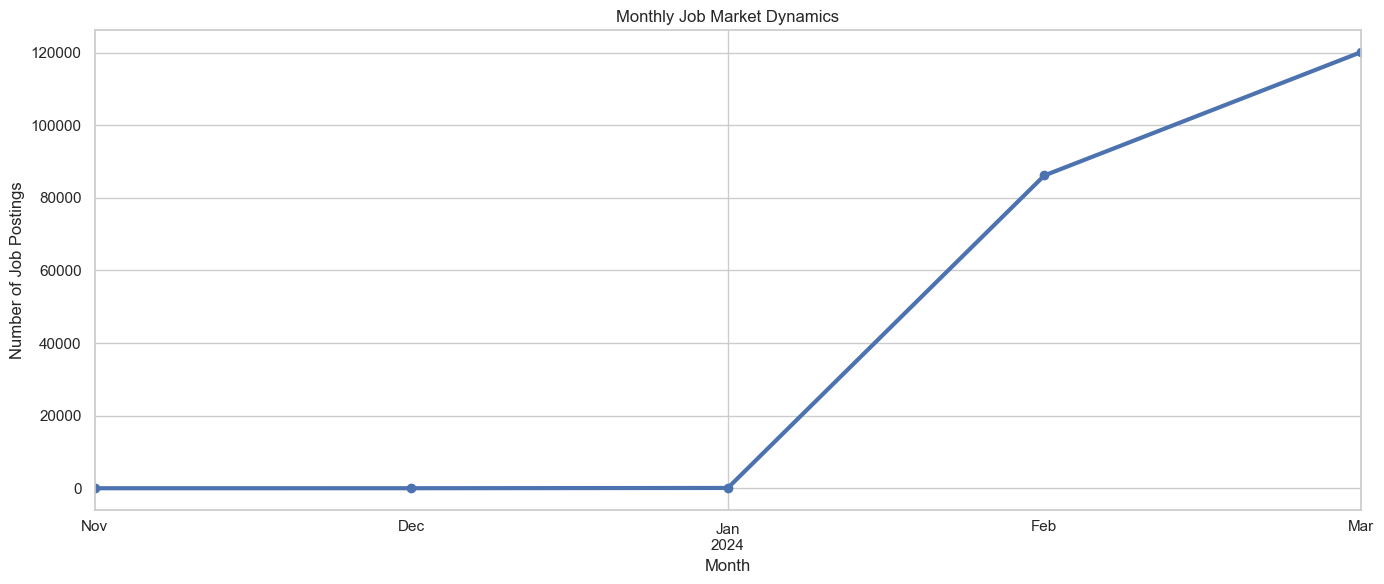

In [ ]:
# 1. Create the 'outputs' directory if it does not exist yet
os.makedirs("outputs", exist_ok=True)

# 2. Parse 'published_date' instead of 'posted_date'
df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce", utc=True
)

df = df.dropna(subset=["published_date"])

# 3. Extract the year-month period cleanly
df["month"] = df["published_date"].dt.tz_localize(None).dt.to_period("M")

# 4. Sort chronologically so the line chart connects months in order
monthly_counts = df.groupby("month").size().sort_index()

plt.figure(figsize=(14, 6))

monthly_counts.plot(marker="o", linewidth=3)

plt.title("Monthly Job Market Dynamics")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")

plt.grid(True)
plt.tight_layout()

plt.savefig("outputs/task6_monthly_trends.png", dpi=300)

plt.show()


* Deliverables:
- Monthly job posting trends.
- Growth and decline analysis.
- Monthly dashboard.

### <span style="color:green"><b>TASK 7: Investigate Trends in the Remote Work Landscape</b></span>

In [ ]:
import numpy as np

title_lower = df["title"].astype(str).str.lower()

conditions = [
    title_lower.str.contains("hybrid", na=False),
    title_lower.str.contains("onsite|on-site|in-office", na=False),
    title_lower.str.contains("remote", na=False),
]
choices = ["Hybrid", "Onsite", "Remote"]

df["work_mode"] = np.select(conditions, choices, default="Not Specified")

print(df["work_mode"].value_counts())


work_mode
Not Specified    205085
Remote             1070
Onsite              103
Hybrid               55
Name: count, dtype: int64


### Visualization:

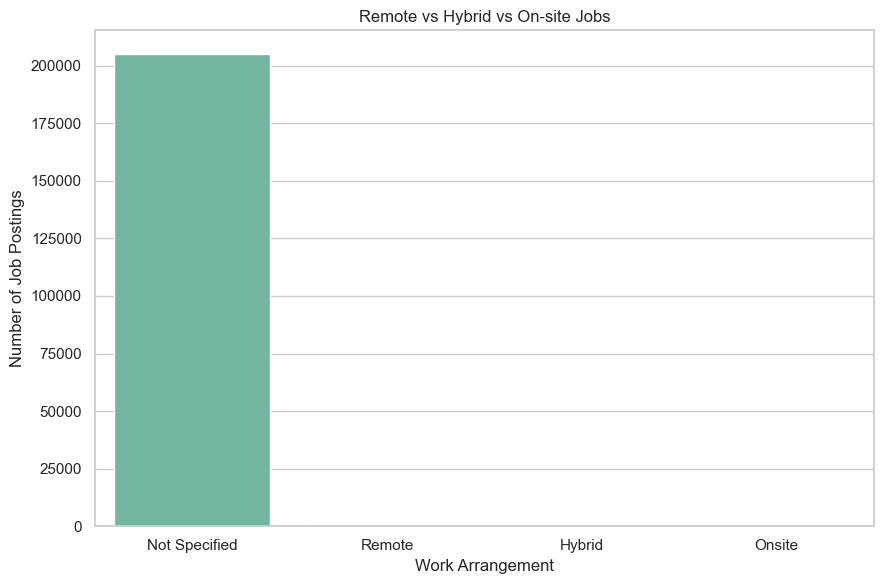

In [ ]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="work_mode",
    hue="work_mode",
    palette="Set2",
    legend=False
)

plt.title("Remote vs Hybrid vs On-site Jobs")

plt.xlabel("Work Arrangement")
plt.ylabel("Number of Job Postings")

plt.tight_layout()

plt.savefig("outputs/task7_remote_work.png")

plt.show()

* Deliverables:
- Remote job frequency.
- Hybrid job frequency.
- On-site job frequency.
- Remote work trends.

### <span style="color:green"><b>TASK 8: Predict Future Job Market Trends</b></span>
Objective: Forecast future job market trends using historical data.

We will use time-series forecasting.

Next 6 Months Forecast:
2024-04-01    109006.513013
2024-05-01    129833.817697
2024-06-01    150661.122382
2024-07-01    171488.427066
2024-08-01    192315.731751
2024-09-01    213143.036436
Freq: MS, dtype: float64


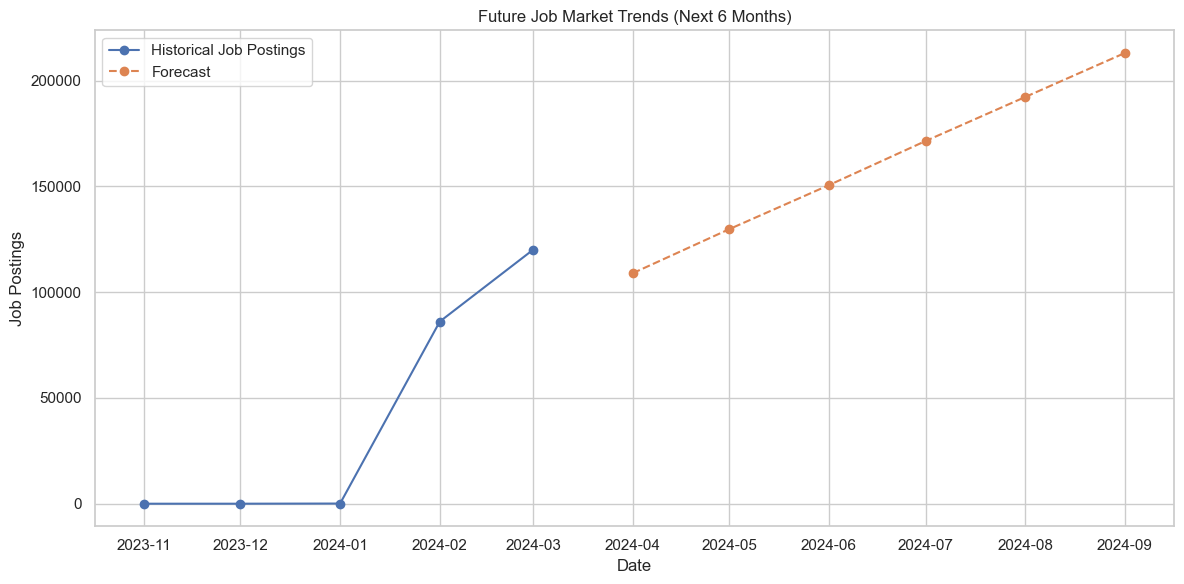

In [9]:
import os
from statsmodels.tsa.holtwinters import ExponentialSmoothing

os.makedirs("outputs", exist_ok=True)

# 1. Parse 'published_date' cleanly
df["published_date"] = pd.to_datetime(
    df["published_date"], errors="coerce", utc=True
)
df = df.dropna(subset=["published_date"])
df["published_date"] = df["published_date"].dt.tz_localize(None)

# 2. Resample by Month Start ('MS'); fall back to Weekly ('W') if fewer than 3 months exist
series = df.set_index("published_date").resample("MS").size()
freq_label = "Months"

if len(series) < 3:
  series = df.set_index("published_date").resample("W").size()
  freq_label = "Weeks"

# 3. Fit Exponential Smoothing model safely
if len(series) >= 2:
  model = ExponentialSmoothing(series, trend="add", seasonal=None)
  fitted_model = model.fit()
  forecast = fitted_model.forecast(6)
else:
  # Fallback if dataset only contains a single time period
  future_index = pd.date_range(
      start=series.index[-1], periods=7, freq="MS"
  )[1:]
  forecast = pd.Series([series.iloc[-1]] * 6, index=future_index)

print(f"Next 6 {freq_label} Forecast:")
print(forecast)

# 4. Plot historical and forecasted trends
plt.figure(figsize=(12, 6))

plt.plot(
    series.index, series.values, marker="o", label="Historical Job Postings"
)
plt.plot(
    forecast.index,
    forecast.values,
    marker="o",
    linestyle="--",
    label="Forecast",
)

plt.title(f"Future Job Market Trends (Next 6 {freq_label})")
plt.xlabel("Date")
plt.ylabel("Job Postings")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("outputs/task8_future_forecast.png", dpi=300)
plt.show()


This is a basic forecasting model. We will validate it against historical data before presenting its predictions as reliable.

## <span style="color:orange"><b>PART 3: Final Project Deployment</b></span>
## 3.1 Introduction

The final deployment phase focused on converting the Job Market Analysis and Recommendation System into a functional web application. The application was developed using Flask and containerized using Docker to make deployment easier and more consistent.

The main objective of this phase was to provide users with an interactive platform where they could access job market insights, explore employment trends, view predictions, and receive relevant job recommendations.

## 3.2 Flask Web Application Development

A web application was developed using the Flask framework in Python. The application provides a user-friendly interface for accessing the results of the job market analysis.

The website includes:
- Job market analysis dashboard.
- Salary analysis and visualizations.
- Emerging job category information.
- Job demand prediction results.
- Job recommendation functionality.
- Job market trend analysis.

The application was tested locally using the Flask development server and accessed through a web browser.

## 3.3 Docker Containerization

Docker was implemented to package the application and its dependencies into containers. This helps maintain a consistent environment and simplifies application deployment.

Two main services were configured:

**1. Flask Application Server (Gunicorn)**

Gunicorn was used as the application server to run the Flask application inside a Docker container. It handles application requests on the internal port 5000.

**2. Nginx Web Server**

Nginx was configured as the web server to receive browser requests and forward them to the Flask application server.

The Nginx service was exposed through port 8080 on the local machine.

## 3.4 Docker Compose Configuration

Docker Compose was used to manage both containers together.

The following services were configured:
- job_prediction_web
- job_prediction_app

Docker Compose made it possible to build, start, stop, and manage both services using simple terminal commands.

## 3.5 Deployment Commands

The following commands were used during deployment:

**Build Docker containers:**

`docker compose build`

**Start the application:**

`docker compose up`

**Run containers in the background:**

`docker compose up -d`

**Check running containers:**

`docker ps`

**View Docker services:**

`docker compose ps`

**Stop and remove containers:**

`docker compose down`

## 3.6 Testing and Verification

After completing the Docker configuration, the application was successfully started using Docker Compose.

Both containers were verified as running:
- job_prediction_web
- job_prediction_app

The web application was accessed successfully through the browser using:

`http://localhost:8080`

The dashboard was checked to confirm that the website was accessible through the Docker environment.

## 3.7 Deployment Architecture

The project follows a two-container deployment architecture:

**User Browser → Nginx Web Server → Flask Application (Gunicorn) → Job Market Analysis System**

The browser sends requests to the Nginx server, which forwards them to the Flask application running through Gunicorn.

This architecture separates the web server from the application server and makes the application easier to manage.

## 3.8 Deployment Outcome

The final deployment was successfully completed in the local Docker environment.

The Flask application was integrated with Gunicorn and Nginx, and both services were managed using Docker Compose. The website became accessible through the local browser at port 8080.

This deployment phase demonstrated the practical use of Flask, Gunicorn, Nginx, Docker, and Docker Compose in developing and running a multi-container web application.

## <span style="color:blue"><b>Conclusion to the project</b></span>
The Job Market Analysis and Recommendation System successfully demonstrates how data analytics, machine learning, and web technologies can be combined to understand current employment trends and support job seekers in making informed career decisions.

Through this project, job posting data was analyzed to identify relationships between job title keywords and offered salaries, discover emerging job categories, predict high-demand job roles, and compare hourly rates across different countries. The project also explored monthly job market changes, remote work trends, and potential future employment opportunities.

A personalized job recommendation system was developed to help users discover relevant job opportunities based on their skills and preferences. Machine learning techniques were applied to analyze historical job posting patterns and predict future demand.

Furthermore, a Flask-based web application was developed to provide an interactive interface for accessing job market insights and recommendations. Docker and Docker Compose were incorporated to containerize the application using separate web server and application server containers, improving consistency and simplifying deployment.

Overall, this project provides a practical solution for understanding job market dynamics, identifying career opportunities, and supporting data-driven decisions for job seekers and recruiters. It also demonstrates the practical application of Python, data analysis, machine learning, Flask, Nginx, and Docker in developing an integrated analytical system.

## <span style="color:green"><b> 1. Importance of the Project</b></span>
The Job Market Analysis and Recommendation System plays an important role in understanding employment trends and helping job seekers and recruiters make better decisions.

### 1.1 Understanding Job Market Trends
The project helps identify changes in job demand, emerging job categories, and popular employment opportunities by analyzing job posting data.

### 1.2 Better Career Decision-Making
Job seekers can use the insights to understand which skills and job roles are in demand and choose suitable career paths.

### 1.3 Salary Analysis
Analyzing salary patterns across job titles and countries helps users understand salary expectations and compare compensation opportunities.

### 1.4 Identifying Emerging Opportunities
The system identifies growing job categories and changing employment patterns, helping users prepare for future career opportunities.

### 1.5 Personalized Job Recommendations
The recommendation engine helps job seekers discover relevant job opportunities based on their skills, interests, and preferences.

### 1.6 Supporting Recruiters and Employers
Recruiters can use job market insights to understand hiring trends, identify high-demand roles, and make better recruitment decisions.

### 1.7 Data-Driven Predictions
Machine learning models help analyze historical job posting patterns and forecast future demand for different job roles.

### 1.8 Easy Accessibility Through Web Technology
The Flask-based web application provides an interactive interface for accessing job market analysis and recommendations. Docker makes application packaging and deployment more consistent.

## <span style="color:green"><b>2. Suggestions for Future Improvement</b></span>

Although the project provides useful job market insights, several improvements can make the system more accurate, efficient, and user-friendly.

### 2.1 Real-Time Job Data Integration
Integrate APIs from job portals to collect updated job postings automatically and provide real-time employment insights.

### 2.2 Advanced Machine Learning Models
Explore advanced algorithms such as XGBoost, Random Forest, LSTM, and transformer-based models to improve job demand forecasting.

### 2.3 Improved Recommendation System
Develop a more advanced recommendation engine that considers skills, qualifications, experience, location, salary expectations, and user preferences.

### 2.4 Interactive Dashboard
Add more interactive charts, filters, search options, and geographical visualizations to improve the user experience.

### 2.5 Skill Gap Analysis
Introduce a feature that compares a user's existing skills with the skills required for a particular job and suggests areas for improvement.

### 2.6 Resume Analysis
Add resume-upload functionality to extract skills and qualifications and recommend suitable job opportunities.

### 2.7 Improved Salary Prediction
Develop machine learning models to estimate expected salaries based on job title, experience, skills, and geographical location.

### 2.8 Cloud Deployment
Deploy the Dockerized application on cloud platforms such as AWS, Azure, or Google Cloud to make it accessible to users from different locations.

### 2.9 Automated Monthly Updates
Implement automated data collection and dashboard updates to continuously monitor changes in job market trends.

### 2.10 User Feedback System
Allow users to provide feedback on job recommendations so that the recommendation engine can be improved over time.

## <span style="color:green"><b>3. Overall Recommendation</b></span>

The Job Market Analysis and Recommendation System has the potential to become a useful platform for job seekers, recruiters, and career planners. By integrating real-time job data, advanced machine learning techniques, personalized recommendations, and cloud deployment, the system can be developed into a more powerful and reliable employment analysis platform.

In [12]:
print("*" * 50)
print("\n📌 Project Name : Job Market Analysis and Recommendation System")
print("👤 Submitted By : Iram Shafi")
print("📅 Date         : 15-November-2026")

print("*" * 50)

**************************************************

📌 Project Name : Job Market Analysis and Recommendation System
👤 Submitted By : Iram Shafi
📅 Date         : 15-November-2026
**************************************************
